# Step 6: Model 3 - PyTorch with fastai (tabular_learner).

In [1]:
# Run from the project root so data/, figures/ and results/ paths work
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%matplotlib inline

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fastai.tabular.all import (
    EarlyStoppingCallback, Normalize, RegressionBlock, SaveModelCallback,
    TabularPandas, rmse, set_seed, tabular_learner,
)

from config import RANDOM_STATE, TARGET
from utils import load_data, evaluate, save_results

set_seed(RANDOM_STATE, reproducible=True)
X_train, X_test, y_train, y_test, X_latest = load_data()
y_col = f"{TARGET}_fwd_ret"
features = list(X_train.columns)

C:\Projects\stock-return-prediction\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Train: 2010-03-31 -> 2023-06-23 (667 rows)
Test : 2023-06-30 -> 2026-10-21 (167 rows)


C:\Projects\stock-return-prediction\.venv\Lib\site-packages\fastai\torch_core.py:155: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:214.)
  else as_tensor(x.values, **kwargs) if isinstance(x, (pd.Series, pd.DataFrame))


[0, 13.167424201965332, 15.073094367980957, 3.882408380508423, '00:00']
Better model found at epoch 0 with valid_loss value: 15.073094367980957.
[1, 11.017067909240723, 15.086770057678223, 3.884169101715088, '00:00']


[2, 10.976153373718262, 15.049552917480469, 3.8793752193450928, '00:00']
Better model found at epoch 2 with valid_loss value: 15.049552917480469.
[3, 10.845155715942383, 14.8058443069458, 3.847836494445801, '00:00']
Better model found at epoch 3 with valid_loss value: 14.8058443069458.
[4, 11.015128135681152, 14.798788070678711, 3.846919536590576, '00:00']
Better model found at epoch 4 with valid_loss value: 14.798788070678711.


[5, 10.910539627075195, 14.821192741394043, 3.849830150604248, '00:00']
[6, 10.884247779846191, 14.894989013671875, 3.859402894973755, '00:00']
[7, 10.981979370117188, 14.852340698242188, 3.8538734912872314, '00:00']


[8, 10.397891998291016, 14.528935432434082, 3.8116841316223145, '00:00']
Better model found at epoch 8 with valid_loss value: 14.528935432434082.
[9, 10.057360649108887, 14.495466232299805, 3.807291269302368, '00:00']
Better model found at epoch 9 with valid_loss value: 14.495466232299805.
[10, 10.012425422668457, 14.879653930664062, 3.8574154376983643, '00:00']


[11, 10.239325523376465, 15.068439483642578, 3.8818087577819824, '00:00']
[12, 9.910223960876465, 15.204544067382812, 3.8993005752563477, '00:00']


... (2 outputs left out)

[18, 9.41136646270752, 15.013856887817383, 3.8747718334198, '00:00']
[19, 9.11446762084961, 14.675088882446289, 3.83080792427063, '00:00']
[20, 9.29342269897461, 14.818131446838379, 3.8494327068328857, '00:00']


[21, 9.645312309265137, 14.781712532043457, 3.8446993827819824, '00:00']
[22, 9.277793884277344, 14.598785400390625, 3.820835828781128, '00:00']


[23, 8.990826606750488, 15.089159965515137, 3.884476900100708, '00:00']
[24, 8.722527503967285, 14.948201179504395, 3.866290330886841, '00:00']
No improvement since epoch 14: early stopping


  model                            fastai
  RMSE                             0.0367
  MAE                              0.0252
  R2                               0.0346
  Directional_Accuracy             0.5928
  Baseline_RMSE                    0.0374
  Baseline_MAE                     0.0256
  Baseline_Directional_Accuracy    0.5629
  train_seconds                    2.7300
  expected_weekly_log_return       0.0159
  expected_weekly_return_pct       1.6064
  expected_annualised_return_pct   129.0334


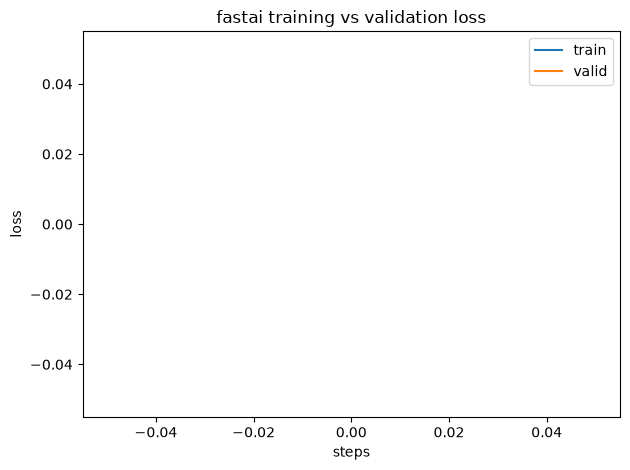

In [3]:
# fastai wants one DataFrame plus a list of which rows are train vs validation
# Target in PERCENT: raw weekly returns (~0.03) are too small for fastai's defaults to learn well
SCALE = 100
train_df = X_train.copy()
train_df[y_col] = y_train * SCALE
n_valid = int(len(train_df) * 0.2)                      # last 20% of training period
splits = (list(range(len(train_df) - n_valid)), list(range(len(train_df) - n_valid, len(train_df))))

to = TabularPandas(train_df.reset_index(drop=True), procs=[Normalize], cont_names=features,
                   y_names=y_col, y_block=RegressionBlock(), splits=splits)
dls = to.dataloaders(bs=32, shuffle=True)

learn = tabular_learner(dls, layers=[64, 32], metrics=rmse)

start = time.time()
with learn.no_bar():
    learn.fit_one_cycle(50, lr_max=1e-3,
                        cbs=[EarlyStoppingCallback(monitor="valid_loss", patience=10),
                             SaveModelCallback(monitor="valid_loss", fname="fastai_best")])
train_seconds = time.time() - start


def predict(X):
    dl = learn.dls.test_dl(X.reset_index(drop=True))
    with learn.no_bar():
        preds, _ = learn.get_preds(dl=dl)
    return preds.numpy().ravel() / SCALE          # back to decimal returns


y_pred = predict(X_test)
metrics = evaluate(y_test, y_pred, y_train)
expected = predict(X_latest)
save_results("fastai", metrics, y_test, y_pred, expected, train_seconds)

learn.recorder.plot_loss()
plt.title("fastai training vs validation loss")
plt.tight_layout(); plt.savefig("figures/fastai_loss.png", dpi=120); plt.show()